### PBR Protocol

For an observed behavior $\vec{P}(a|x)$ where (with slight abuse of notation) $a = (a, b, \dots)$ and $x = (x, y, \dots)$, we'd like to test the consistency of the null hypothesis $\mathcal{H}_0 = \vec{P} \in \mathcal{NS}$. The steps are as follows

**Fit** First, from our observed frequencies $\vec{f}(a|x) := N(a,x) / N(x)$, we minimize the following problem
$$P^*_{\mathcal{NS}} = \min_{P \in \mathcal{NS}} D_{KL}(f||P)$$
This gives us the closest distribution in $\mathcal{NS}$ to our experimental data. To constrain $P \in \mathcal{NS}$, one uses the following linear constraints:

$$\mathcal{NS}_{B \nrightarrow A} := \sum_b P(a, b|x, y) = \sum_b(a, b|x, y')$$
$$\mathcal{NS}_{A \nrightarrow B} := \sum_a P(a, b|x, y) = \sum_a(a, b|x', y)$$

The class $\mathcal{NS} = \mathcal{NS}_{B \nrightarrow A} \cap \mathcal{NS}_{A \nrightarrow B}$ is the combination of those constraints.

From this, we can now compute the value

$$R(a,x) := \frac{\vec{f}(a|x)}{P_{\mathcal{NS}}^*(a|x)}$$

**Test** Given some new data $\mathcal{D} = \{(x_1, a_1), \dots, (x_n, a_n)\}$, we compute the statistic

$$t = \prod_{x,a \in \mathcal{D}} R(a,x)$$

and the upper bound p-value is given by $p_U = \min(t^{-1}, 1)$.

In [4]:
import itertools
from collections import Counter

import cvxpy as cp
import numpy as np
from sklearn.base import BaseEstimator


class NonSignalingRegression(BaseEstimator):
    def __init__(self, players: int, questions: int, answers: int, P_x: np.ndarray | None = None):
        if players > 2:
            raise NotImplementedError("No support yet for more than 2 players")
        
        self.players = players
        self.questions = questions
        self.answers = answers

        shape = self.players*(self.questions,)

        # If not provided, assume all questions asked uniformly
        if P_x is None:
            P_x = np.ones(shape)
            P_x /= P_x.size
        else:
            if P_x.shape != shape:
                raise ValueError(f"Expected input distribution P(x) with shape {shape}, got {P_x.shape}")
            
        self.P_x = P_x
        self._kl_div = 0
        self._R: np.ndarray = None
    
    def fit(self, X: np.ndarray, y: np.ndarray | None = None):
        # X should be rows of the form (x, y, a, b)
        if X.ndim != 2 or X.shape[1] != 2 * self.players:
            raise ValueError(f"Expected sample array of shape (n, 2*players), got: {X.shape}")

        # Sparse structure: only store distribution for values we can actually get
        query_set = set(tuple(map(int, x)) for x in zip(*self.P_x.nonzero()))
        self._query_to_idx = {k: i for i, k in enumerate(query_set)}

        answer_set: set[tuple[int, ...]] = set(itertools.product(range(self.answers), repeat=self.players))
        self._answer_to_idx = {k: i for i, k in enumerate(answer_set)}

        # Obtain the (normalized) frequencies f(a|x)
        f_xa_dict = self._get_frequencies(X)
        
        # Convert frequencies to an array
        shape = (len(query_set), len(answer_set))
        f_xa = np.zeros(shape, dtype=float)
        for x in query_set:
            for a in answer_set:
                xa = x + a
                f_xa[self._query_to_idx[x], self._answer_to_idx[a]] = f_xa_dict.get(xa, 0)

        # Construct the convex optimization problem, here we assume all questions are equally likely
        P = cp.Variable(shape, nonneg=True)

        P_x = np.zeros((len(query_set), 1))
        nonzero_indices = self.P_x.nonzero()

        for x in zip(*nonzero_indices):
            x = tuple(map(int, x))
            P_x[self._query_to_idx[x]] = self.P_x[*x]

        # Note that CVXPY's rel_entr is the correct kl divergence definition: https://github.com/cvxpy/cvxpy/issues/733
        kl = cp.rel_entr(f_xa, P)
        rescaled_kl = cp.multiply(P_x, kl)
        objective = cp.Minimize(cp.sum(rescaled_kl))
        constraints = self._get_constraints(P)
        problem = cp.Problem(objective, constraints)

        # Solve and store the results
        self._kl_div = problem.solve(solver=cp.SCS)
        p_star = P.value
        self._R = f_xa / (p_star + 1e-9)
    
    def predict(self, X: np.ndarray):
        if X.ndim != 2 or X.shape[1] != 2 * self.players:
            raise ValueError(f"Expected sample array of shape (n, 2*players), got: {X.shape}")

        result = np.zeros(X.shape[0])

        # Given samples (x, a), return the values R(x, a)
        for i, row in enumerate(X.astype(int)):
            xa = tuple(map(int, row))
            x, a = xa[:self.players], xa[self.players:]

            # If this question was never in our training data, we have no way to
            # return any prediction
            if (xi := self._query_to_idx.get(x, None)) is None:
                raise ValueError(f"Query {x} was not in training data")
            
            # If this pair (x, a) wasn't in the training data, which can happen
            # for low probability pairs, then f(a|x) = 0 => R(a|x) = 0
            elif (ai := self._answer_to_idx.get(a, None)) is None:
                result[i] = 0

            else:
                result[i] = self._R[xi, ai]

        return result
    
    def _get_idx(self, xa: tuple[int, ...]):
        x, a = xa[:self.players], xa[self.players:]

        xi = self._query_to_idx[x]
        ai = self._answer_to_idx[a]
        return xi, ai
        
    def _get_constraints(self, P: cp.Variable):
        constraints: list[cp.Constraint] = []

        query_set = set(self._query_to_idx)
        answer_set = set(self._answer_to_idx)

        # Proper probability sum_{a} p(a|x) = 1
        for x in query_set:
            samples = []
            for a in answer_set:
                xi, ai = self._get_idx(x + a)
                samples.append(P[xi, ai])
            
            constraints.append(cp.sum(samples) == 1)
        
        # No-signaling constraints. We pick any 2 distinct question pairs (x, y) and (x', y').
        for (x, y), (x_prime, y_prime) in itertools.combinations(query_set, 2):
            # When x = x', there's the constraint that Alice's answer a cannot depend on changing bob's
            # question y. So we constrain that P(a|x, y) = P(a|x, y') (marginalizing over b)
            if x == x_prime:
                for a in range(self.answers):
                    samples = [P[*self._get_idx((x, y, a, b))] for b in range(self.answers)]
                    lhs = cp.sum(samples)

                    samples = [P[*self._get_idx((x, y_prime, a, b))] for b in range(self.answers)]
                    rhs = cp.sum(samples)
                    constraints.append(lhs == rhs)
            
            # Same idea, when y = y', Bob's answer cannot depend on Alice's question. P(b|x, y) = P(b|x', y)
            elif y == y_prime:
                for b in range(self.answers):
                    samples = [P[*self._get_idx((x, y, a, b))] for a in range(self.answers)]
                    lhs = cp.sum(samples)

                    samples = [P[*self._get_idx((x_prime, y, a, b))] for a in range(self.answers)]
                    rhs = cp.sum(samples)
                    constraints.append(lhs == rhs)

            # If neither are equal, then there's no constraint.

        return constraints

    def _get_frequencies(self, X: np.ndarray):
        raw_samples: list[list[int]] = X.astype(int).tolist()
        N_xa = Counter(map(tuple, raw_samples))

        raw_queries: list[list[int]] = X[..., :self.players].astype(int).tolist()
        N_x = Counter(map(tuple, raw_queries))

        f_xa: dict[tuple[int, ...], float] = {}
        for xa in N_xa:
            x = xa[:self.players]
            f_xa[xa] = N_xa.get(xa, 0) / N_x.get(x, 0)

        return f_xa

def pvalue_score(y: np.ndarray):
    # Any entries where y = 0 imply that f(a|x) = 0, which means it wasn't
    # in our training data. Therefore, we filter out those examples, which
    # arise from finite shots.
    log_y = np.log(y[y > 0])
    log_t = log_y.sum()
    t = np.exp(log_t)
    return min(t ** -1, 1)

To evaluate the implementation above, we first test on fake CHSH data with and without crosstalk to see if the algorithm detects the difference.

- **Nonsignaling strategy**: We use the deterministic classical strategy that maximizes the game win probability, where Alice and Bob always return $a = b = 0$.
- **Signaling strategy**: A strategy where Bob's answer is Alice's question, $b = x$. This requires signaling from Alice to Bob. Alice uses a random answer.

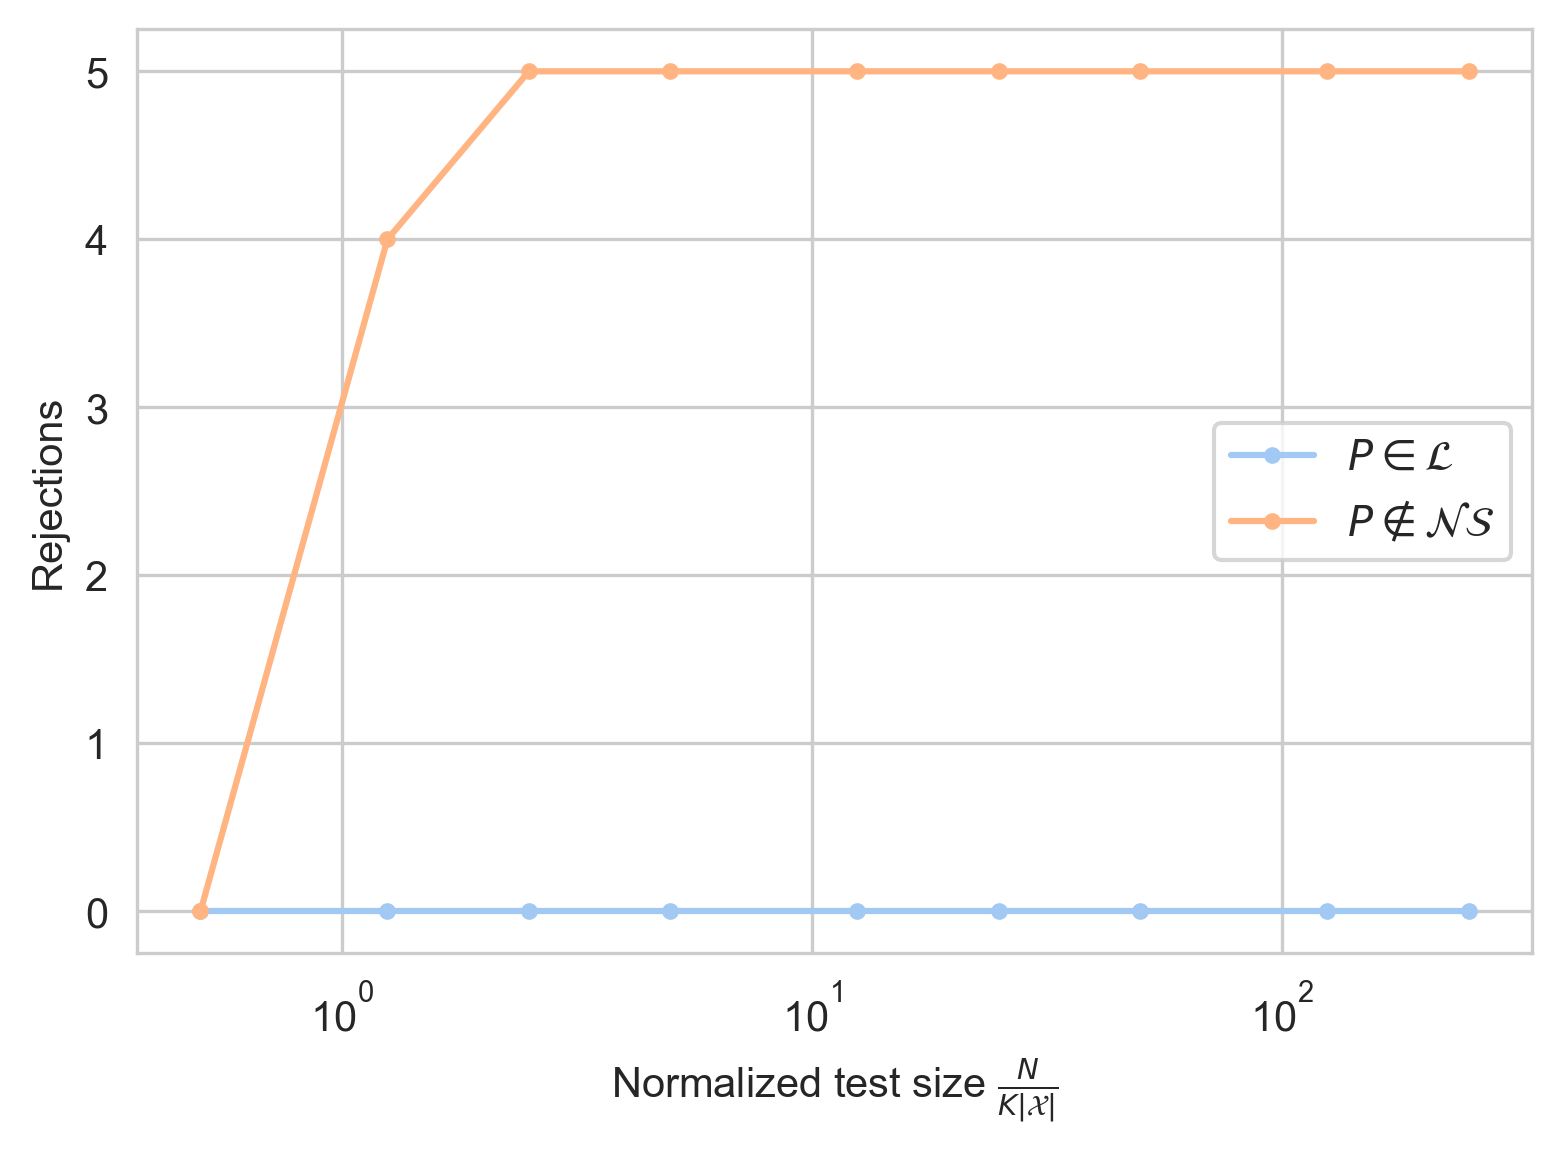

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import KFold

def random_chsh_nonsignaling_data(N: int):
    X = np.zeros((N, 4))
    
    # Alice's and Bob's questions are random
    questions = np.random.randint(0, 2, (N, 2))

    # Deterministic classical strategy: a = b = 0
    # (don't need to do anything)

    X[:, :2] = questions
    return X

def random_chsh_signaling_data(N: int):
    X = np.zeros((N, 4))
    
    # Alice's and Bob's questions are random
    questions = np.random.randint(0, 2, (N, 2))
    
    # Alice's answer is random
    alice_answer = np.random.randint(0, 2, (N, 1))
    
    # Bob's answer is a direct copy of Alice's question (x)
    bob_answer = questions[:, 0].reshape(N, 1)
    
    answers = np.hstack([alice_answer, bob_answer])
    
    X[:, :2] = questions
    X[:, 2:] = answers
    
    return X

K = 5
N_vals = np.array([10, 25, 50, 100, 250, 500, 1000, 2500, 5000])
signaling_rejections = np.zeros_like(N_vals)
nonsignaling_rejections = np.zeros_like(N_vals)
for i, N in enumerate(N_vals):
    kf = KFold(n_splits=K)

    X = random_chsh_signaling_data(N)
    for j, (train_indices, test_indices) in enumerate(kf.split(X)):
        model = NonSignalingRegression(2, 2, 2)
        model.fit(X[train_indices])
        y = model.predict(X[test_indices])

        if (pvalue := pvalue_score(y)) < 0.05:
            signaling_rejections[i] += 1
    
    X = random_chsh_nonsignaling_data(N)
    for j, (train_indices, test_indices) in enumerate(kf.split(X)):
        model = NonSignalingRegression(2, 2, 2)
        model.fit(X[train_indices])
        y = model.predict(X[test_indices])

        if (pvalue := pvalue_score(y)) < 0.05:
            nonsignaling_rejections[i] += 1

x = N_vals / (K * 4) # |X| = 4 queries
sns.set_palette("pastel")
sns.set_style("whitegrid")
plt.figure(figsize=(6, 4), dpi=300)
plt.plot(x, nonsignaling_rejections, '.-', label=r"$P \in \mathcal{L}$")
plt.plot(x, signaling_rejections, '.-', label=r"$P \notin \mathcal{NS}$")
plt.xscale('log')
plt.xlabel(r"Normalized test size $\frac{N}{K|\mathcal{X}|}$")
plt.ylabel("Rejections")
plt.legend()
plt.show()

Now we'll evaluate the nonsignaling metric on the Blue ion trap, the only one that beat the game.

In [2]:
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

df = pd.read_csv("../data/processed_data/trapped_ion/duke_gold.csv")
df.head()

,x0,x1,win_rate,a0,a1,count
0,0,0,0.873333,0,0,62
1,0,0,0.873333,1,0,0
2,0,0,0.873333,2,0,2
3,0,0,0.873333,3,0,1
4,0,0,0.873333,0,1,2


From this, we construct our dataset of individual rounds. This is a numpy array where each row is a round, and the first 2 columns are the question $\mathbf{x} := (x, y)$, and the last 2 columns are the answers $\mathbf{a} := (a, b)$

In [11]:
samples = []

for _, row in df.iterrows():
    x = (int(row['x0']), int(row['x1']))
    a = (int(row['a0']), int(row['a1']))
    n = int(row['count'])
    val = np.array(x + a, dtype=int)
    samples.extend([val] * n)

X = np.array(samples)
X

array([[ 0,  0,  0,  0],
       [ 0,  0,  0,  0],
       [ 0,  0,  0,  0],
       ...,
       [13, 12,  2,  3],
       [13, 12,  2,  3],
       [13, 12,  3,  3]], shape=(15300, 4))

Now we repeat the k-fold cross validation as before with the real data and check how many rejections we get.

In [12]:
from sklearn.model_selection import KFold
import pandas as pd

# Construct P_x since our graph structure is sparse
P_x = np.zeros((14, 14))
for _, row in df.iterrows():
    x = (int(row['x0']), int(row['x1']))
    P_x[x] = 1
P_x /= P_x.sum()

α = 0.05
kf = KFold(n_splits=5, shuffle=True)
for i, (train, test) in enumerate(kf.split(X)):
    model = NonSignalingRegression(2, 14, 4, P_x=P_x)
    model.fit(X[train])
    y = model.predict(X[test])
    print(pd.Series(y).describe(percentiles=[0.01, 0.1, 0.25, 0.5, 0.75, 0.9, 0.99]))
    p_value = pvalue_score(y)

    print(f"Fold {i}: kl={model._kl_div:.4e}, p={p_value:.4f}, reject={p_value < α}")

count    3060.000000
mean        0.995027
std         0.165175
min         0.000000
1%          0.527220
10%         0.825726
25%         0.914534
50%         1.000578
75%         1.079105
90%         1.177502
99%         1.329043
max         1.665307
dtype: float64
Fold 0: kl=9.8704e-03, p=1.0000, reject=False
count    3060.000000
mean        0.993757
std         0.162671
min         0.000000
1%          0.621091
10%         0.817322
25%         0.914698
50%         0.992548
75%         1.091713
90%         1.167528
99%         1.356785
max         1.620281
dtype: float64
Fold 1: kl=1.0053e-02, p=1.0000, reject=False
count    3060.000000
mean        0.997128
std         0.156044
min         0.000000
1%          0.615238
10%         0.826420
25%         0.909018
50%         0.996952
75%         1.093522
90%         1.182218
99%         1.323292
max         1.521014
dtype: float64
Fold 2: kl=9.9465e-03, p=1.0000, reject=False
count    3060.000000
mean        0.993623
std         0.16435